# Evaluation

## 1. Setup

### 1.1. Imports, Drive y Rutas

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import json, math, os, re, time
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = Path('/content/drive/MyDrive/NoteVision')
RAW_DIR = PROJECT_DIR / 'data_raw'
ARTIFACTS_DIR = PROJECT_DIR / 'artifacts'
LOCAL_DIR = Path('/content/primus')
ARCHIVE = RAW_DIR / 'primus.tgz'
EXPECTED_SAMPLES = 87_678
SEED = 42

def count_samples(root):
    n = 0
    for pkg in ('package_aa', 'package_ab'):
        p = root / pkg
        if p.exists():
            n += sum(1 for d in p.iterdir() if d.is_dir() and not d.name.startswith('._'))
    return n

if count_samples(LOCAL_DIR) != EXPECTED_SAMPLES:
    LOCAL_DIR.mkdir(parents=True, exist_ok=True)
    !tar -xzf $ARCHIVE -C $LOCAL_DIR

n = count_samples(LOCAL_DIR)
print('Samples on disk:', n)
assert n == EXPECTED_SAMPLES, 'Incomplete extraction'

gpus = tf.config.list_physical_devices('GPU')
print('GPUs:', gpus)  # inference works on CPU too, but use the T4 runtime for speed
for g in gpus:
    tf.config.experimental.set_memory_growth(g, True)
tf.keras.utils.set_random_seed(SEED)

Mounted at /content/drive
Samples on disk: 87678
GPUs: []


### 1.2. Definition from 03-Modeling

In [2]:
IMG_HEIGHT = 128
REDUCTION = 8
CTC_BLANK = 0  # class 0 = blank; token id i -> class i + 1
BOUNDS = list(range(600, 2201, 100)) + [2600, 3000, 3600]
MAX_PIXELS = 48000
MAX_BATCH = 64
BATCH_SIZES = [max(4, min(MAX_BATCH, MAX_PIXELS // b)) for b in BOUNDS] + [4]

def load_vocab(vocab_csv):
    df = pd.read_csv(vocab_csv, dtype=str, keep_default_na=False)
    tokens = df['token'].tolist()
    return tokens, {t: i for i, t in enumerate(tokens)}, len(tokens)

def encode_labels(df, token_to_id, max_len):
    labels = np.zeros((len(df), max_len), dtype=np.int32)
    lengths = np.zeros(len(df), dtype=np.int32)
    for i, seq in enumerate(df['label']):
        ids = [token_to_id[t] for t in seq.split()]
        labels[i, :len(ids)] = ids
        lengths[i] = len(ids)
    return labels, lengths

def decode_ids(ids, tokens):
    return ' '.join(tokens[i] for i in ids)

def image_path(root, package, sid):
    return Path(root) / package / sid / f'{sid}.png'

def load_image(path):
    raw = tf.io.read_file(path)
    img = tf.io.decode_png(raw, channels=3)  # palette (mode P) -> RGB
    gray = tf.image.rgb_to_grayscale(img)
    h = tf.cast(tf.shape(gray)[0], tf.float32)
    w = tf.cast(tf.shape(gray)[1], tf.float32)
    new_w = tf.maximum(1, tf.cast(tf.round(w * IMG_HEIGHT / h), tf.int32))
    gray = tf.image.resize(tf.cast(gray, tf.float32), (IMG_HEIGHT, new_w),
                           method='bilinear', antialias=True)
    gray = tf.clip_by_value(gray, 0.0, 255.0)
    return 1.0 - gray / 255.0, new_w  # ink = 1, background/padding = 0

class CRNN(keras.Model):
    def __init__(self, num_classes, lstm_units=128, dropout=0.25, **kw):
        super().__init__(**kw)
        filters = (32, 64, 128, 256)
        pools = ((2, 2), (2, 2), (2, 2), (2, 1))
        self.convs = [layers.Conv2D(f, 3, padding='same', use_bias=False) for f in filters]
        self.bns = [layers.BatchNormalization() for _ in filters]
        self.pools = [layers.MaxPool2D(p) for p in pools]
        self.proj = layers.Dense(256, activation='relu')
        self.drop = layers.Dropout(dropout)
        self.rnn1 = layers.Bidirectional(layers.LSTM(lstm_units, return_sequences=True))
        self.rnn2 = layers.Bidirectional(layers.LSTM(lstm_units, return_sequences=True))
        self.classifier = layers.Dense(num_classes)

    def call(self, inputs, training=False):
        x, widths = inputs['image'], inputs['width']
        for conv, bn, pool in zip(self.convs, self.bns, self.pools):
            x = pool(tf.nn.relu(bn(conv(x), training=training)))
        x = tf.transpose(x, [0, 2, 1, 3])
        s = tf.shape(x)
        x = tf.reshape(x, [s[0], s[1], x.shape[2] * x.shape[3]])
        x = self.drop(self.proj(x), training=training)
        logit_len = widths // REDUCTION
        mask = tf.sequence_mask(logit_len, maxlen=s[1])
        x = self.rnn1(x, mask=mask, training=training)
        x = self.rnn2(self.drop(x, training=training), mask=mask, training=training)
        return self.classifier(self.drop(x, training=training)), logit_len

def greedy_decode(logits, lengths, blank=CTC_BLANK):
    ids = np.argmax(logits, axis=-1)
    out = []
    for seq, n in zip(ids, lengths):
        seq = seq[:n]
        changed = np.concatenate([[True], seq[1:] != seq[:-1]])
        seq = seq[changed]
        out.append((seq[seq != blank] - 1).tolist())
    return out

def make_infer(model):
    @tf.function(input_signature=[tf.TensorSpec([None, IMG_HEIGHT, None, 1], tf.float32),
                                  tf.TensorSpec([None], tf.int32)])
    def infer(image, width):
        return model({'image': image, 'width': width}, training=False)
    return infer

def build_eval_dataset(df, root, token_to_id, max_label_len):
    """Same bucketed pipeline as validation in 03, plus the row index to restore order."""
    labels, lengths = encode_labels(df, token_to_id, max_label_len)
    paths = [str(image_path(root, p, i)) for p, i in zip(df['package'], df['id'])]
    idx = np.arange(len(df), dtype=np.int32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels, lengths, idx))

    def _map(path, label, length, i):
        image, width = load_image(path)
        return {'image': image, 'width': width, 'label': label,
                'label_length': length, 'idx': i}

    ds = ds.map(_map, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.bucket_by_sequence_length(
        element_length_func=lambda e: e['width'],
        bucket_boundaries=BOUNDS, bucket_batch_sizes=BATCH_SIZES,
        padded_shapes={'image': [IMG_HEIGHT, None, 1], 'width': [],
                       'label': [max_label_len], 'label_length': [], 'idx': []},
        padding_values={'image': tf.constant(0.0), 'width': tf.constant(0, tf.int32),
                        'label': tf.constant(0, tf.int32),
                        'label_length': tf.constant(0, tf.int32),
                        'idx': tf.constant(0, tf.int32)},
        pad_to_bucket_boundary=True, drop_remainder=False)
    return ds.prefetch(tf.data.AUTOTUNE)

def predict_indexed(infer, ds, n):
    hyps, widths = [None] * n, np.zeros(n, dtype=np.int32)
    for b in ds:
        logits, logit_len = infer(b['image'], b['width'])
        out = greedy_decode(logits.numpy(), logit_len.numpy())
        for i, h, w in zip(b['idx'].numpy(), out, b['width'].numpy()):
            hyps[i] = h
            widths[i] = w
    assert all(h is not None for h in hyps), 'some samples were not predicted'
    return hyps, widths

def align_pairs(ref, hyp):
    """Edit distance + ops (op, ref_token, hyp_token); same tie-breaking as the 03 align."""
    if ref == hyp:
        return 0, [('hit', t, t) for t in ref]
    n, m = len(ref), len(hyp)
    d = [[0] * (m + 1) for _ in range(n + 1)]
    for i in range(n + 1):
        d[i][0] = i
    for j in range(m + 1):
        d[0][j] = j
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            d[i][j] = min(d[i-1][j] + 1, d[i][j-1] + 1,
                          d[i-1][j-1] + (ref[i-1] != hyp[j-1]))
    ops, i, j = [], n, m
    while i > 0 or j > 0:
        if i > 0 and j > 0 and d[i][j] == d[i-1][j-1] + (ref[i-1] != hyp[j-1]):
            ops.append(('hit' if ref[i-1] == hyp[j-1] else 'sub', ref[i-1], hyp[j-1]))
            i, j = i - 1, j - 1
        elif i > 0 and d[i][j] == d[i-1][j] + 1:
            ops.append(('del', ref[i-1], None))
            i -= 1
        else:
            ops.append(('ins', None, hyp[j-1]))
            j -= 1
    ops.reverse()
    return d[n][m], ops

def align(ref, hyp):
    d, ops = align_pairs(ref, hyp)
    return d, [(op, r) for op, r, _ in ops]

def evaluate_sequences(refs, hyps, families):
    tot_ref = tot_err = tot_err_shape = exact = 0
    per_fam = defaultdict(Counter)
    for r, h in zip(refs, hyps):
        dist, ops = align(r, h)
        tot_err += dist
        tot_ref += len(r)
        exact += int(r == h)
        tot_err_shape += align([families[i] for i in r], [families[i] for i in h])[0]
        for op, tok in ops:
            if tok is not None:
                per_fam[families[tok]][op] += 1
    metrics = {'cer': tot_err / tot_ref, 'seq_acc': exact / len(refs),
               'cer_shape': tot_err_shape / tot_ref,
               'n_sequences': len(refs), 'n_tokens': tot_ref}
    rows = []
    for fam, c in per_fam.items():
        support = c['hit'] + c['sub'] + c['del']
        rows.append({'family': fam, 'support': support, 'recall': c['hit'] / support})
    fam_df = pd.DataFrame(rows).sort_values('support', ascending=False).reset_index(drop=True)
    return metrics, fam_df

# Sanity checks
_m, _ = evaluate_sequences([[0, 1, 2]], [[0, 0, 2]], ['a', 'a', 'b'])
assert abs(_m['cer'] - 1/3) < 1e-9 and _m['cer_shape'] == 0.0 and _m['seq_acc'] == 0.0
_d, _ops = align_pairs([0, 1, 2], [0, 2])
assert _d == 1 and _ops == [('hit', 0, 0), ('del', 1, None), ('hit', 2, 2)]
print('Definitions OK.')

Definitions OK.


### 1.3. Bootstrap

In [3]:
val = pd.read_csv(ARTIFACTS_DIR / 'split_val.csv', dtype=str)
val['seq_len'] = val['seq_len'].astype(int)
tokens, token_to_id, _ = load_vocab(ARTIFACTS_DIR / 'vocab_agnostic.csv')
cfg = json.loads((ARTIFACTS_DIR / 'preprocessing_config.json').read_text())
summ = json.loads((ARTIFACTS_DIR / 'split_summary.json').read_text())
assert IMG_HEIGHT == cfg['img_height'] and len(tokens) == cfg['vocab_size']
assert len(val) == summ['n_val']
MAX_LABEL_LEN = cfg['max_label_len']
NUM_CLASSES = len(tokens) + 1

families = [t.split('-')[0] for t in tokens]   # symbol without position, e.g. 'note.quarter'
kinds = [f.split('.')[0] for f in families]    # coarse kind, e.g. 'note'

POS_RE = re.compile(r'^([LS])(-?\d+)$')
def token_step(tok):
    """Staff step: space below line 1 = 0; line k -> 2k-1; space k -> 2k. None if no position."""
    m = POS_RE.match(tok.partition('-')[2])
    if m is None:
        return None
    n = int(m.group(2))
    return 2 * n - 1 if m.group(1) == 'L' else 2 * n
steps = [token_step(t) for t in tokens]
print('Val:', len(val), '| tokens:', len(tokens), '| tokens with a parsed position:',
      sum(s is not None for s in steps))

Val: 8772 | tokens: 758 | tokens with a parsed position: 758


## 2. Load EXP-00

In [4]:
EXP_ID = 'EXP-00'
RUN_DIR = ARTIFACTS_DIR / 'checkpoints' / 'exp00'
OUT_DIR = ARTIFACTS_DIR / f"eval_{EXP_ID.lower().replace('-', '')}_val"
OUT_DIR.mkdir(exist_ok=True)
BASELINE_CER = 0.91  # trivial predictors, approx. (STATUS.md)

def read_run_config(run_dir):
    ptr = json.loads((run_dir / 'latest.json').read_text())
    return json.loads((run_dir / ptr['slot'] / 'state.json').read_text())['config']

def load_experiment(run_dir):
    run_cfg = read_run_config(run_dir)
    model = CRNN(NUM_CLASSES, lstm_units=run_cfg['lstm_units'], dropout=run_cfg['dropout'])
    model({'image': tf.zeros([1, IMG_HEIGHT, 256, 1]), 'width': tf.constant([256])})  # build weights
    model.load_weights(run_dir / 'best.weights.h5')
    best = json.loads((run_dir / 'best.json').read_text())
    return model, make_infer(model), best, run_cfg

model, infer, best, run_cfg = load_experiment(RUN_DIR)
print(EXP_ID, '| best epoch', int(best['epoch']), '| params', f'{model.count_params():,}',
      '| subset CER in training log', round(best['val_cer'], 4))

EXP-00 | best epoch 8 | params 1,897,367 | subset CER in training log 0.0073


## 3. Inference on full validation set

In [5]:
t0 = time.time()
ds_val = build_eval_dataset(val, LOCAL_DIR, token_to_id, MAX_LABEL_LEN)
hyps, widths = predict_indexed(infer, ds_val, len(val))
refs = [[token_to_id[t] for t in s.split()] for s in val['label']]
print(f'{len(val)} images in {time.time() - t0:.0f}s')

metrics, fam_df = evaluate_sequences(refs, hyps, families)
print(f"FULL VAL | CER {metrics['cer']:.4f} | seq_acc {metrics['seq_acc']:.4f} | "
      f"cer_shape {metrics['cer_shape']:.4f} | {metrics['n_sequences']} sequences, "
      f"{metrics['n_tokens']} tokens | trivial baseline CER ~ {BASELINE_CER}")

# Cross-check against the 2 000-sample subset used during training
sub_ids = pd.read_csv(ARTIFACTS_DIR / 'val_subset_ids.csv', dtype=str)
sub_keys = set(sub_ids['package'] + '/' + sub_ids['id'])
mask = (val['package'] + '/' + val['id']).isin(sub_keys).to_numpy()
m_sub, _ = evaluate_sequences([r for r, k in zip(refs, mask) if k],
                              [h for h, k in zip(hyps, mask) if k], families)
diff = abs(m_sub['cer'] - best['val_cer'])
print(f"Subset ({int(mask.sum())}) CER recomputed {m_sub['cer']:.4f} vs training log "
      f"{best['val_cer']:.4f} -> {'OK' if diff < 1e-3 else 'CHECK: differs by ' + str(round(diff, 5))}")

8772 images in 1704s
FULL VAL | CER 0.0067 | seq_acc 0.8805 | cer_shape 0.0054 | 8772 sequences, 240867 tokens | trivial baseline CER ~ 0.91
Subset (2000) CER recomputed 0.0073 vs training log 0.0073 -> OK


## 4. Error analysis

In [6]:
def analyze_errors(refs, hyps):
    rows = []
    fam_stats = defaultdict(Counter)  # family of the REF token -> hit / sub_position / sub_shape / del
    confusions = Counter()            # (ref_token, hyp_token) substitutions
    inserted = Counter()              # predicted tokens with no reference counterpart
    shifts = Counter()                # staff-step shift for same-symbol, different-position errors
    totals = Counter()
    for i, (r, h) in enumerate(zip(refs, hyps)):
        dist, ops = align_pairs(r, h)
        n_sub = n_del = n_ins = 0
        for op, rt, ht in ops:
            if op == 'hit':
                fam_stats[families[rt]]['hit'] += 1
            elif op == 'sub':
                n_sub += 1
                if families[rt] == families[ht]:
                    cat = 'sub_position'
                    if steps[rt] is not None and steps[ht] is not None:
                        shifts[steps[ht] - steps[rt]] += 1
                else:
                    cat = 'sub_shape'
                fam_stats[families[rt]][cat] += 1
                confusions[(rt, ht)] += 1
                totals[cat] += 1
            elif op == 'del':
                n_del += 1
                fam_stats[families[rt]]['del'] += 1
                totals['del'] += 1
            else:
                n_ins += 1
                inserted[ht] += 1
                totals['ins'] += 1
        rows.append((i, len(r), len(h), dist, n_sub, n_del, n_ins))
    per_sample = pd.DataFrame(rows, columns=['idx', 'ref_len', 'hyp_len', 'dist',
                                             'n_sub', 'n_del', 'n_ins'])
    return per_sample, fam_stats, confusions, inserted, shifts, totals

def family_table(stats, key_fn=lambda f: f):
    agg = defaultdict(Counter)
    for fam, c in stats.items():
        agg[key_fn(fam)].update(c)
    rows = []
    for k, c in agg.items():
        support = c['hit'] + c['sub_position'] + c['sub_shape'] + c['del']
        rows.append({'family': k, 'support': support,
                     'recall': c['hit'] / support,
                     'recall_shape': (c['hit'] + c['sub_position']) / support,
                     'pos_errors': c['sub_position'], 'shape_errors': c['sub_shape'],
                     'missed': c['del']})
    return pd.DataFrame(rows).sort_values('support', ascending=False).reset_index(drop=True)

per_sample, fam_stats, confusions, inserted, shifts, totals = analyze_errors(refs, hyps)
per_sample['width'] = widths

# Consistency with the official metric
n_tok = int(per_sample['ref_len'].sum())
total_err = sum(totals[k] for k in ('sub_position', 'sub_shape', 'del', 'ins'))
assert total_err == int(per_sample['dist'].sum())
assert abs(total_err / n_tok - metrics['cer']) < 1e-12, 'decomposition does not match CER'
fine = family_table(fam_stats)
chk = fam_df.merge(fine, on='family', suffixes=('_a', '_b'))
assert (chk['support_a'] == chk['support_b']).all() and np.allclose(chk['recall_a'], chk['recall_b'])
print('Decomposition consistent with evaluate_sequences.')

Decomposition consistent with evaluate_sequences.


## 5. Error decomposition

In [7]:
pd.set_option('display.width', 200)
order = ['sub_position', 'sub_shape', 'del', 'ins']
labels_es = {'sub_position': 'same symbol, wrong position', 'sub_shape': 'wrong symbol',
             'del': 'missed (deletion)', 'ins': 'extra (insertion)'}
dec = pd.DataFrame({'type': [labels_es[k] for k in order],
                    'count': [totals[k] for k in order],
                    'rate_vs_ref_tokens': [totals[k] / n_tok for k in order],
                    'share_of_errors': [totals[k] / total_err for k in order]})
print(f"CER = {total_err / n_tok:.4f}  (= sum of the rates below)")
display(dec.round(4))

print('\nPosition shift in staff steps (hyp - ref) for "same symbol, wrong position":')
sh = pd.DataFrame(sorted(shifts.items()), columns=['shift', 'count'])
sh['share'] = sh['count'] / sh['count'].sum()
display(sh.round(3))

print('\nTop 20 substitutions (ref -> hyp):')
conf = pd.DataFrame([{'ref': tokens[r], 'hyp': tokens[h], 'count': c,
                      'type': 'position' if families[r] == families[h] else 'symbol'}
                     for (r, h), c in confusions.most_common(20)])
display(conf)

print('\nMost missed families / most inserted tokens:')
missed = sorted(((f, c['del']) for f, c in fam_stats.items() if c['del']), key=lambda x: -x[1])[:10]
display(pd.DataFrame(missed, columns=['family (missed)', 'count']))
display(pd.DataFrame([(tokens[t], c) for t, c in inserted.most_common(10)],
                     columns=['token (inserted)', 'count']))

CER = 0.0067  (= sum of the rates below)


,type,count,rate_vs_ref_tokens,share_of_errors
0,"same symbol, wrong position",266,0.0011,0.1658
1,wrong symbol,145,0.0006,0.0904
2,missed (deletion),700,0.0029,0.4364
3,extra (insertion),493,0.0020,0.3074



Position shift in staff steps (hyp - ref) for "same symbol, wrong position":


,shift,count,share
0,-6,1,0.004
1,-5,1,0.004
2,-4,1,0.004
3,-3,1,0.004
4,-2,43,0.162
5,-1,87,0.327
6,1,78,0.293
7,2,48,0.180
8,3,1,0.004
9,4,3,0.011



Top 20 substitutions (ref -> hyp):


,ref,hyp,count,type
0,gracenote.sixteenth-L4,gracenote.sixteenth-S3,15,position
1,note.quarter-S6,note.quarter-S5,12,position
2,gracenote.sixteenth-L4,gracenote.sixteenth-S4,10,position
3,gracenote.sixteenth-S4,gracenote.sixteenth-L4,9,position
4,gracenote.sixteenth-S3,gracenote.sixteenth-L3,7,position
5,gracenote.sixteenth-S3,gracenote.sixteenth-L4,7,position
6,gracenote.sixteenth-S5,gracenote.sixteenth-L6,7,position
7,gracenote.sixteenth-L5,gracenote.sixteenth-S4,6,position
8,gracenote.sixteenth-S5,gracenote.sixteenth-L5,6,position
9,gracenote.sixteenth-L6,gracenote.sixteenth-S5,6,position



Most missed families / most inserted tokens:


,family (missed),count
0,accidental.natural,336
1,barline,116
2,accidental.flat,110
3,slur.end,42
4,slur.start,35
5,accidental.sharp,25
6,gracenote.sixteenth,17
7,gracenote.thirty_second,4
8,dot,2
9,clef.G,1


,token (inserted),count
0,barline-L1,216
1,slur.start-L3,16
2,slur.start-S5,14
3,slur.end-S5,14
4,slur.end-L4,14
5,slur.start-L6,14
6,slur.start-L5,13
7,slur.end-L5,13
8,slur.end-L6,13
9,slur.end-S4,13


## 6. Recall by symbol family

In [8]:
MIN_SUPPORT = 100
coarse = family_table(fam_stats, key_fn=lambda f: f.split('.')[0])
print('By coarse kind (recall = exact token; recall_shape ignores position):')
display(coarse.round(4))

print('\nTop 25 families by support:')
display(fine.head(25).round(4))

print(f'\nWorst 15 families by recall (support >= {MIN_SUPPORT}):')
display(fine[fine['support'] >= MIN_SUPPORT].sort_values('recall').head(15).round(4))

By coarse kind (recall = exact token; recall_shape ignores position):


,family,support,recall,recall_shape,pos_errors,shape_errors,missed
0,note,133595,0.9991,0.9994,35,79,6
1,barline,32594,0.9963,0.9963,0,4,116
2,accidental,17331,0.9710,0.9717,13,19,471
3,rest,13114,0.9998,0.9998,0,1,1
4,dot,11826,0.9994,0.9997,3,2,2
5,digit,11175,0.9992,0.9992,0,8,1
6,clef,8849,0.9994,0.9994,0,2,3
7,metersign,4796,1.0000,1.0000,0,0,0
8,slur,2594,0.9680,0.9680,0,6,77
9,multirest,2294,0.9996,0.9996,0,1,0



Top 25 families by support:


,family,support,recall,recall_shape,pos_errors,shape_errors,missed
0,note.quarter,34243,0.9993,0.9998,16,7,1
1,barline,32594,0.9963,0.9963,0,4,116
2,note.eighth,22655,0.9997,1.0000,6,1,0
3,note.beamedRight1,13475,0.9999,1.0000,1,0,0
4,dot,11826,0.9994,0.9997,3,2,2
5,note.half,11387,0.9996,0.9998,2,2,0
6,note.beamedLeft1,10168,0.9998,0.9999,1,1,0
7,note.beamedBoth2,9003,0.9998,0.9998,0,2,0
8,note.beamedLeft2,8806,0.9997,0.9998,1,2,0
9,accidental.sharp,8457,0.9954,0.9965,9,5,25



Worst 15 families by recall (support >= 100):


,family,support,recall,recall_shape,pos_errors,shape_errors,missed
35,gracenote.sixteenth,700,0.7471,0.9671,154,6,17
26,accidental.natural,1489,0.7683,0.7696,2,7,336
29,slur.end,1297,0.9645,0.9645,0,4,42
28,slur.start,1297,0.9715,0.9715,0,2,35
11,accidental.flat,7385,0.9839,0.9842,2,7,110
46,digit.9,144,0.9931,0.9931,0,1,0
45,note.thirty_second,164,0.9939,0.9939,0,1,0
33,digit.1,1027,0.9942,0.9942,0,5,1
40,note.double_whole,356,0.9944,0.9972,1,0,1
9,accidental.sharp,8457,0.9954,0.9965,9,5,25


## 7. Errors by sequence length and image width

In [9]:
def cer_by(col, bins):
    g = per_sample.assign(bin=bins).groupby('bin', observed=True).agg(
        n=('idx', 'size'), dist=('dist', 'sum'), ref=('ref_len', 'sum'),
        seq_acc=('dist', lambda s: (s == 0).mean()))
    g['cer'] = g['dist'] / g['ref']
    return g[['n', 'ref', 'dist', 'cer', 'seq_acc']].round(4)

print('By reference length (tokens):')
display(cer_by('ref_len', pd.cut(per_sample['ref_len'], [0, 20, 40, 60, MAX_LABEL_LEN])))
print('\nBy image width after resize (quintiles):')
display(cer_by('width', pd.qcut(per_sample['width'], 5, duplicates='drop')))

By reference length (tokens):


,n,ref,dist,cer,seq_acc
bin,,,,,
"(0, 20]",1296,22610,170,0.0075,0.9128
"(20, 40]",7145,203623,1280,0.0063,0.8810
"(40, 60]",329,14511,152,0.0105,0.7447
"(60, 75]",2,123,2,0.0163,0.5000



By image width after resize (quintiles):


,n,ref,dist,cer,seq_acc
bin,,,,,
"(360.999, 918.0]",1764,41206,291,0.0071,0.8883
"(918.0, 1072.0]",1752,46314,294,0.0063,0.8864
"(1072.0, 1219.0]",1750,49314,279,0.0057,0.9006
"(1219.0, 1433.0]",1753,51073,325,0.0064,0.8859
"(1433.0, 3417.0]",1753,52960,415,0.0078,0.8414


## 8. REF/HYP examples

=== 6 worst samples ===
idx 643 | package_aa/000105627-1_1_1 | 18 ref tokens | 9 edit(s)
  before ref[10] (extra) note.quarter-L4
  ref[10] note.beamedRight0-L4  ->  note.quarter-L5
  ref[11] note.beamedBoth0-L5  ->  note.quarter-S4
  ref[12] note.beamedBoth0-S4  ->  note.quarter-L4
  ref[13] note.beamedLeft0-L4  ->  note.quarter-L4
  ref[14] note.beamedRight0-L4  ->  note.quarter-L3
  ref[15] note.beamedLeft0-L3  ->  note.quarter-S3
  ref[16] note.beamedRight0-S3  ->  note.quarter-S4
  ref[17] note.beamedLeft0-S4  ->  barline-L1
REF: clef.G-L2 metersign.C-L3 note.quarter-S2 barline-L1 note.quarter-S4 note.quarter-S3 note.quarter-L3 rest.quarter-L3 note.quarter-L3 barline-L1 note.beamedRight0-L4 note.beamedBoth0-L5 note.beamedBoth0-S4 note.beamedLeft0-L4 note.beamedRight0-L4 note.beamedLeft0-L3 note.beamedRight0-S3 note.beamedLeft0-S4
HYP: clef.G-L2 metersign.C-L3 note.quarter-S2 barline-L1 note.quarter-S4 note.quarter-S3 note.quarter-L3 rest.quarter-L3 note.quarter-L3 barline-L1 note.

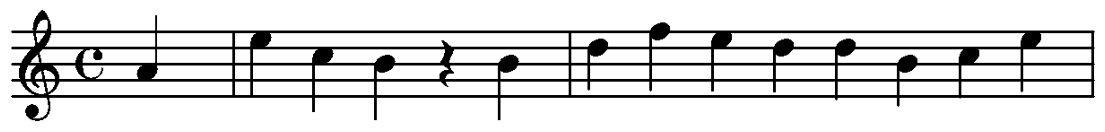

idx 6646 | package_ab/211008488-1_37_1 | 29 ref tokens | 8 edit(s)
  ref[4] gracenote.thirty_second-L-1  ->  gracenote.thirty_second-L0
  ref[5] gracenote.thirty_second-S-1  ->  gracenote.thirty_second-L0
  ref[8] gracenote.thirty_second-L0  ->  gracenote.thirty_second-S0
  ref[9] gracenote.thirty_second-S-1  ->  gracenote.sixteenth-L0
  ref[10] gracenote.thirty_second-L-1  ->  gracenote.sixteenth-L-1
  ref[13] gracenote.thirty_second-S-1  ->  gracenote.thirty_second-S0
  ref[14] gracenote.thirty_second-L-1  ->  gracenote.sixteenth-L0
  ref[15] gracenote.thirty_second-L0  ->  gracenote.sixteenth-L-1
REF: clef.G-L2 accidental.flat-L3 accidental.flat-S4 metersign.C/-L3 gracenote.thirty_second-L-1 gracenote.thirty_second-S-1 gracenote.thirty_second-L0 note.half-S-1 gracenote.thirty_second-L0 gracenote.thirty_second-S-1 gracenote.thirty_second-L-1 note.half-S-1 barline-L1 gracenote.thirty_second-S-1 gracenote.thirty_second-L-1 gracenote.thirty_second-L0 note.half-S-1 rest.quarter-L3 note.b

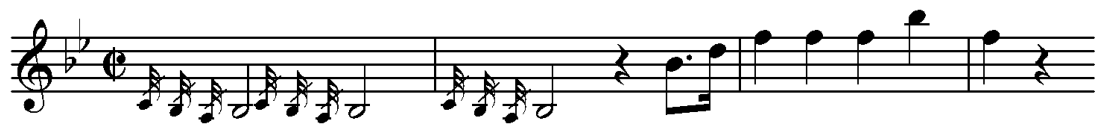

idx 6595 | package_ab/211008117-1_2_1 | 28 ref tokens | 7 edit(s)
  ref[5] slur.end-S3  ->  slur.start-L3
  ref[7] slur.start-S3  ->  slur.end-L3
  before ref[9] (extra) slur.start-L3
  before ref[12] (extra) slur.start-L3
  ref[14] slur.end-S3  ->  (missing)
  ref[16] slur.start-S3  ->  (missing)
  before ref[27] (extra) slur.end-L4
REF: clef.C-L1 metersign.C/-L3 note.whole-S3 slur.start-S3 note.whole-L3 slur.end-S3 note.whole-S3 slur.start-S3 note.whole-L3 note.whole-S2 note.whole-L3 note.whole-L3 note.whole-L4 note.whole-S4 slur.end-S3 note.whole-S3 slur.start-S3 slur.end-S3 note.whole-S3 slur.start-S3 note.whole-L3 slur.end-S3 note.whole-S3 slur.start-S3 note.whole-L4 slur.end-S3 note.whole-S3 note.whole-L4
HYP: clef.C-L1 metersign.C/-L3 note.whole-S3 slur.start-S3 note.whole-L3 slur.start-L3 note.whole-S3 slur.end-L3 note.whole-L3 slur.start-L3 note.whole-S2 note.whole-L3 note.whole-L3 slur.start-L3 note.whole-L4 note.whole-S4 note.whole-S3 slur.end-S3 note.whole-S3 slur.start-S3 

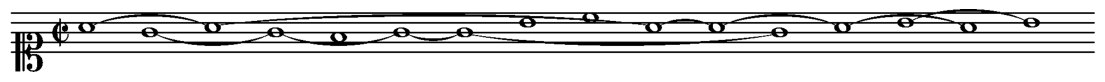

idx 785 | package_aa/000106909-1_2_1 | 20 ref tokens | 7 edit(s)
  ref[11] note.beamedRight0-S5  ->  note.quarter-S5
  ref[12] note.beamedBoth0-S3  ->  note.quarter-S3
  ref[13] note.beamedLeft0-L4  ->  note.quarter-L4
  ref[14] note.beamedRight0-S4  ->  note.quarter-S4
  ref[15] note.beamedBoth0-S5  ->  note.quarter-S5
  ref[16] note.beamedBoth0-S3  ->  note.quarter-S3
  ref[17] note.beamedLeft0-L4  ->  note.quarter-L4
REF: clef.F-L4 accidental.sharp-L4 metersign.C-L3 rest.eighth-L3 note.eighth-S5 note.quarter-S5 rest.eighth-L3 note.eighth-S5 note.quarter-S5 barline-L1 rest.quarter-L3 note.beamedRight0-S5 note.beamedBoth0-S3 note.beamedLeft0-L4 note.beamedRight0-S4 note.beamedBoth0-S5 note.beamedBoth0-S3 note.beamedLeft0-L4 barline-L1 note.quarter-S4
HYP: clef.F-L4 accidental.sharp-L4 metersign.C-L3 rest.eighth-L3 note.eighth-S5 note.quarter-S5 rest.eighth-L3 note.eighth-S5 note.quarter-S5 barline-L1 rest.quarter-L3 note.quarter-S5 note.quarter-S3 note.quarter-L4 note.quarter-S4 note.

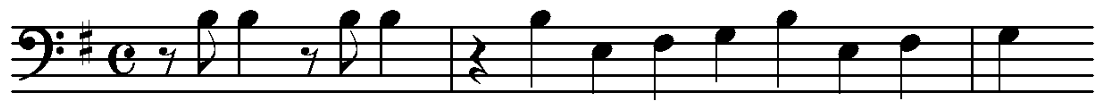

idx 6530 | package_ab/211007103-1_8_1 | 37 ref tokens | 7 edit(s)
  ref[7] accidental.natural-S-1  ->  accidental.natural-L-1
  ref[10] note.beamedLeft4-L0  ->  note.beamedLeft3-L0
  ref[14] accidental.flat-S-1  ->  (missing)
  ref[15] note.beamedBoth4-S-1  ->  (missing)
  ref[16] accidental.natural-L0  ->  note.beamedBoth4-S0
  ref[17] note.beamedLeft4-L0  ->  note.beamedLeft3-L0
  ref[22] note.beamedLeft4-L0  ->  note.beamedLeft3-L0
REF: clef.G-L2 accidental.flat-L3 digit.3-L4 digit.4-L2 note.beamedRight1-S0 rest.sixteenth-L3 note.beamedBoth3-L-1 accidental.natural-S-1 note.beamedBoth4-S-1 accidental.sharp-L0 note.beamedLeft4-L0 note.beamedRight1-S0 rest.sixteenth-L3 note.beamedBoth3-L-1 accidental.flat-S-1 note.beamedBoth4-S-1 accidental.natural-L0 note.beamedLeft4-L0 note.beamedRight1-S0 rest.sixteenth-L3 note.beamedBoth3-L-1 note.beamedBoth4-S-1 note.beamedLeft4-L0 barline-L1 note.sixteenth-S0 note.beamedRight2-S2 note.beamedBoth2-S2 note.beamedLeft2-S2 note.beamedRight2-S2 note.b

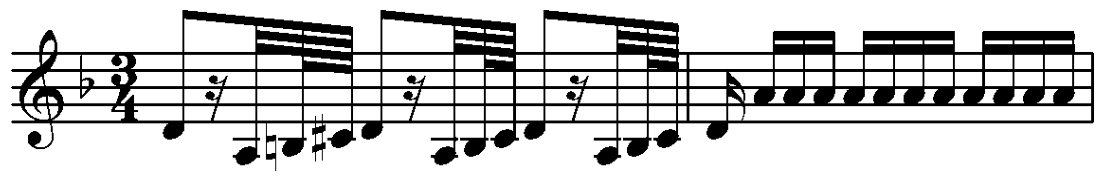

idx 3314 | package_aa/000131651-1_1_1 | 46 ref tokens | 7 edit(s)
  ref[4] gracenote.sixteenth-L3  ->  gracenote.sixteenth-S0
  ref[5] gracenote.sixteenth-S0  ->  gracenote.sixteenth-L3
  ref[28] note.beamedRight4-S5  ->  note.beamedRight3-S5
  ref[29] note.beamedBoth4-L6  ->  note.beamedBoth3-L6
  ref[34] note.beamedRight4-S5  ->  note.beamedRight3-S5
  ref[35] note.beamedBoth4-L6  ->  note.beamedBoth3-L6
  ref[41] gracenote.sixteenth-L4  ->  gracenote.sixteenth-S4
REF: clef.G-L2 accidental.flat-L3 accidental.flat-S4 metersign.C-L3 gracenote.sixteenth-L3 gracenote.sixteenth-S0 note.beamedRight1-L5 dot-S5 note.beamedLeft2-S6 note.eighth-L4 rest.eighth-L3 dot-S3 note.beamedRight2-L4 note.beamedBoth2-S3 note.beamedLeft2-L4 note.beamedRight2-S4 note.beamedBoth2-S3 note.beamedBoth2-S5 dot-S5 note.beamedLeft3-L3 barline-L1 gracenote.eighth-L3 note.beamedRight1-S2 dot-S2 note.beamedBoth3-L3 note.beamedLeft3-S3 note.eighth-L3 rest.eighth-L3 note.beamedRight4-S5 note.beamedBoth4-L6 note.beamed

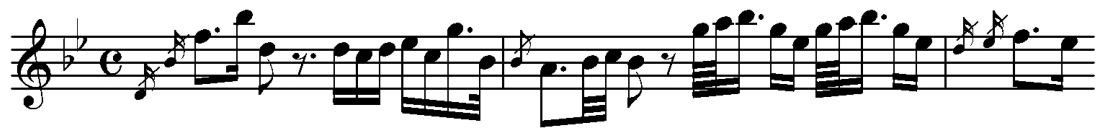


=== 6 random samples with 1-2 edits (typical errors) ===
idx 7509 | package_ab/220015260-1_1_1 | 24 ref tokens | 2 edit(s)
  ref[9] slur.start-L5  ->  (missing)
  ref[11] slur.end-L5  ->  (missing)


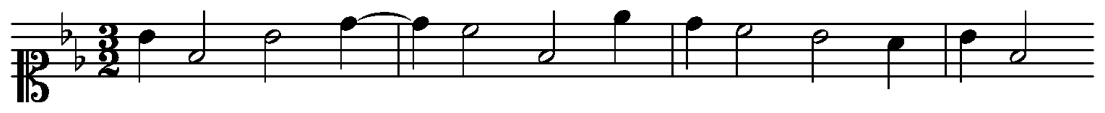

idx 572 | package_aa/000105061-14_1_1 | 25 ref tokens | 2 edit(s)
  ref[21] slur.start-S4  ->  (missing)
  ref[23] slur.end-S4  ->  (missing)


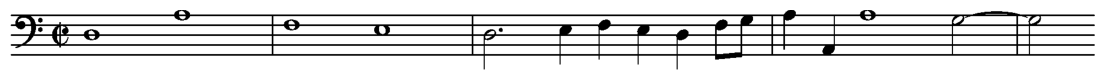

idx 5913 | package_ab/201009226-1_2_1 | 46 ref tokens | 2 edit(s)
  ref[13] note.quarter-S2  ->  note.beamedRight1-S2
  ref[21] accidental.natural-S4  ->  (missing)


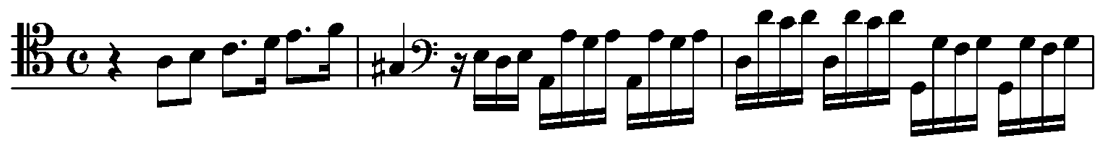

idx 4763 | package_ab/190004109-1_1_1 | 40 ref tokens | 1 edit(s)
  ref[16] gracenote.sixteenth-S5  ->  gracenote.sixteenth-L6


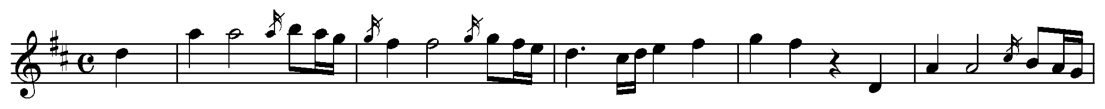

idx 7666 | package_ab/220017450-1_11_1 | 21 ref tokens | 1 edit(s)
  before ref[21] (extra) barline-L1


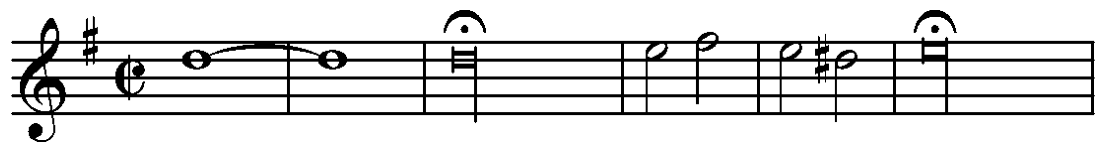

idx 702 | package_aa/000106316-1_1_1 | 21 ref tokens | 1 edit(s)
  before ref[21] (extra) barline-L1


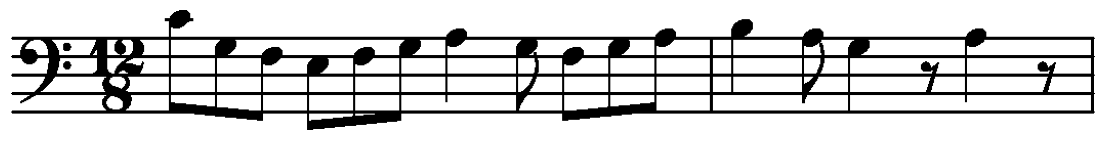

In [10]:
def edit_script(ref, hyp):
    dist, ops = align_pairs(ref, hyp)
    out, k = [], 0
    for op, rt, ht in ops:
        if op == 'hit':
            k += 1
        elif op == 'sub':
            out.append(f'  ref[{k}] {tokens[rt]}  ->  {tokens[ht]}')
            k += 1
        elif op == 'del':
            out.append(f'  ref[{k}] {tokens[rt]}  ->  (missing)')
            k += 1
        else:
            out.append(f'  before ref[{k}] (extra) {tokens[ht]}')
    return out

def show_example(i, full=False):
    row = val.iloc[i]
    print(f"idx {i} | {row['package']}/{row['id']} | {len(refs[i])} ref tokens | "
          f"{int(per_sample.loc[i, 'dist'])} edit(s)")
    print('\n'.join(edit_script(refs[i], hyps[i])))
    if full:
        print('REF:', decode_ids(refs[i], tokens))
        print('HYP:', decode_ids(hyps[i], tokens))
    img = Image.open(image_path(LOCAL_DIR, row['package'], row['id'])).convert('L')
    plt.figure(figsize=(14, 3)); plt.imshow(img, cmap='gray'); plt.axis('off'); plt.show()

print('=== 6 worst samples ===')
for i in per_sample.sort_values('dist', ascending=False).head(6)['idx']:
    show_example(int(i), full=True)

print('\n=== 6 random samples with 1-2 edits (typical errors) ===')
small = per_sample[per_sample['dist'].between(1, 2)]
for i in small.sample(min(6, len(small)), random_state=SEED)['idx']:
    show_example(int(i))

## 9. Save results

In [11]:
def to_py(x):
    return float(x) if isinstance(x, (np.floating, float)) else int(x)

summary = {
    'exp_id': EXP_ID, 'split': 'val_full', 'best_epoch': int(best['epoch']),
    'metrics': {k: to_py(v) for k, v in metrics.items()},
    'subset_check': {'cer_recomputed': float(m_sub['cer']), 'cer_training_log': float(best['val_cer'])},
    'error_rates': {k: totals[k] / n_tok for k in order},
    'error_counts': {k: int(totals[k]) for k in order},
}
(OUT_DIR / 'metrics_val.json').write_text(json.dumps(summary, indent=1))
fine.to_csv(OUT_DIR / 'recall_by_family.csv', index=False)
coarse.to_csv(OUT_DIR / 'recall_by_kind.csv', index=False)
errs = per_sample[per_sample['dist'] > 0].copy()
errs['package'] = val['package'].to_numpy()[errs['idx']]
errs['id'] = val['id'].to_numpy()[errs['idx']]
errs['ref'] = [decode_ids(refs[i], tokens) for i in errs['idx']]
errs['hyp'] = [decode_ids(hyps[i], tokens) for i in errs['idx']]
errs.to_csv(OUT_DIR / 'errors_val.csv', index=False)
print('Saved to', OUT_DIR)
print(f"{EXP_ID} full val | CER {metrics['cer']:.4f} | seq_acc {metrics['seq_acc']:.4f} | "
      f"cer_shape {metrics['cer_shape']:.4f}")

Saved to /content/drive/MyDrive/NoteVision/artifacts/eval_exp00_val
EXP-00 full val | CER 0.0067 | seq_acc 0.8805 | cer_shape 0.0054
